# E-Commerce Sales & Customer Segmentation Analysis

In [1]:
pip install pyodbc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pyodbc 
import pandas as pd

## 1. SQL Server Connection & Data Loading

In [3]:
conn_str = ("driver={ODBC Driver 18 for SQL Server};"
            "server=localhost;"
            "database=customers;"
            "Trusted_Connection=yes;"
            "TrustServerCertificate=yes;"
           )

In [4]:
conn = pyodbc.connect(conn_str)
data = "select * from clean_retail_data"
df = pd.read_sql(data, conn)
conn.close()
print(df.head())

C:\Users\DELL\AppData\Local\Temp\ipykernel_21736\4233336440.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(data, conn)


  Invoice StockCode                     Description  Quantity  Price  \
0  491062     20730            STRAWBERRY CANDY BAG        20   1.25   
1  491062     21100  CHARLIE AND LOLA CHARLOTTE BAG        30   1.65   
2  491063    79303D   LILAC FLOWER BLOCK TABLE LAMP        20   2.95   
3  491063     21477        STRING OF 20 ROSE LIGHTS         4  12.75   
4  491063     85042       ANTIQUE LILY FAIRY LIGHTS         4   4.95   

   Customer_ID         Country  Total_Revenue  
0      12948.0  United Kingdom           25.0  
1      12948.0  United Kingdom           49.5  
2      16771.0  United Kingdom           59.0  
3      16771.0  United Kingdom           51.0  
4      16771.0  United Kingdom           19.8  


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 805531 entries, 0 to 805530
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Invoice        805531 non-null  str    
 1   StockCode      805531 non-null  str    
 2   Description    805531 non-null  str    
 3   Quantity       805531 non-null  int64  
 4   Price          805531 non-null  float64
 5   Customer_ID    805531 non-null  float64
 6   Country        805531 non-null  str    
 7   Total_Revenue  805531 non-null  float64
dtypes: float64(3), int64(1), str(4)
memory usage: 88.4 MB


## 2. Data Cleaning & Filtering Non-Product Codes

In [6]:
stock= ['POST', 'M', 'DOT', 'BANK CHARGES', 'ADJUST']
clean_stock= df[~df['StockCode'].isin(stock)].copy()

## 3. Customer Segmentation (FM Analysis)

In [7]:
clean_stock ['Customer_ID']= clean_stock['Customer_ID'].astype(int)

In [8]:
fm_analysis=clean_stock.groupby('Customer_ID').agg(

 Frequency=('Invoice', 'nunique'), 
    Monetary=('Total_Revenue', 'sum') 
).reset_index()

In [9]:
fm_analysis['Segment']=pd.qcut(
    fm_analysis['Monetary'],
    q=3,
    labels=['Silver', 'Gold', 'VIP']
)
print(fm_analysis.head(5))

   Customer_ID  Frequency  Monetary Segment
0        12346         12  77556.46     VIP
1        12347          8   5633.32     VIP
2        12348          5   1658.40     VIP
3        12349          3   3678.69     VIP
4        12350          1    294.40  Silver


## 4. Exploratory Data Visualization

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
sns.set_theme(style="whitegrid")

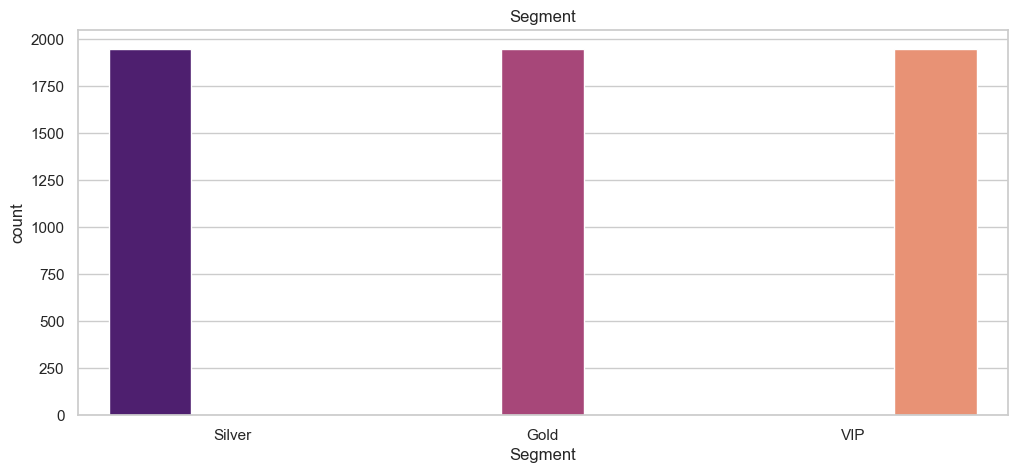

In [12]:
plt.figure(figsize=(12, 5))
sns.countplot(data=fm_analysis,x='Segment',palette='magma',hue='Segment', legend=False)
plt.title('Segment')
plt.show()

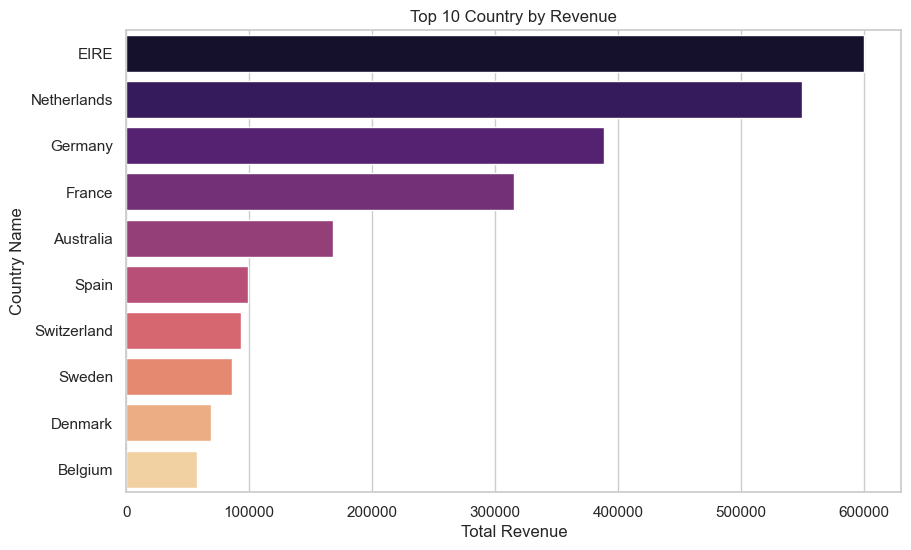

In [13]:
top= (
    clean_stock[clean_stock['Country']!='United Kingdom']
    .groupby('Country')['Total_Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()    
    )
plt.figure(figsize=(10, 6))
sns.barplot(
data=top,
x='Total_Revenue',
y='Country',
hue='Country',   
palette='magma', 
legend=False
)
plt.title('Top 10 Country by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country Name')
plt.show()




In [14]:
clean_stock.to_csv('clean_retail.csv', index=False)

fm_analysis.to_csv('customer_segments.csv', index=False)

print("OK")


OK
